In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from mltools.seg.dataset import SegDataset
from mltools import PROCESSED_DIR
from pathlib import Path

dataset = SegDataset(Path(PROCESSED_DIR) / "logs_Min256", cache_amount=0)

/home/matic/mltools/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Caching data...: 0it [00:00, ?it/s]


In [ ]:
from matplotlib import pyplot as plt


def show_case(image, mask):

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.title("Image")
    plt.imshow(image)
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.title("Mask")
    plt.imshow(mask, cmap="gray", vmin=0, vmax=1)
    plt.axis("off")

    plt.show()

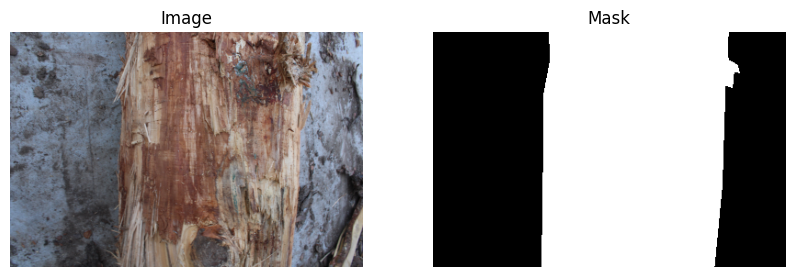

In [4]:
image, mask = dataset[0]
show_case(image, mask)

In [ ]:
import cv2
import numpy as np
from scipy.stats import norm


def apply_vignette(image, mask, amount=0.5):
    """
    Applies a contour-aware vignette.
    amount: 0.0 (no effect) to 1.0 (full mask falloff)
    """
    if amount <= 0 or not np.any(mask):
        return image
    if amount >= 1:
        return image * (mask > 0)

    # mask should be uint8 (0 and 255)
    dist = cv2.distanceTransform(~mask, cv2.DIST_L2, 5)

    # normalize to [0, 1]
    # cv2.normalize(dist, dist, 0, 1.0, cv2.NORM_MINMAX)

    # The kernel size should be proportional to image resolution
    blur_size = int(image.shape[0] * 0.05) | 1  # Must be odd
    vignette_map = cv2.GaussianBlur(dist, (blur_size, blur_size), 0)
    print(blur_size)

    # apply bell curve for falloff control
    scale = min(image.shape[0:2]) * 0.5
    vignette_map = norm.cdf(vignette_map, loc=0, scale=(scale * (1 - amount)))
    vignette_map = 1 - vignette_map
    cv2.normalize(vignette_map, vignette_map, 0, 1.0, cv2.NORM_MINMAX)

    # add channel dimension for broadcasting if image is RGB
    if len(image.shape) == 3:
        vignette_map = vignette_map[:, :, np.newaxis]

    # apply to image
    # ensure image is float for multiplication
    result = (image.astype(np.float32) * vignette_map).astype(np.uint8)

    return result

13


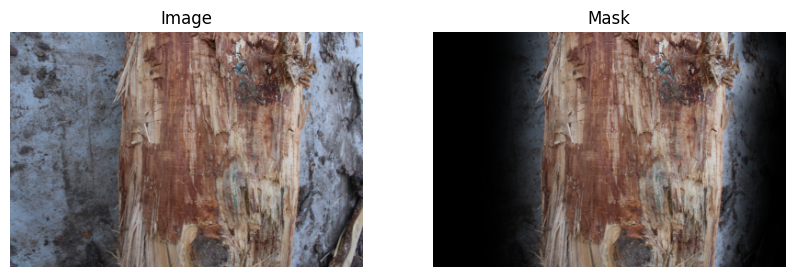

In [6]:
vignette = apply_vignette(image, (mask * 255).astype(np.uint8), amount=0.8)
show_case(image, vignette)
# show_case(vignette, mask)

In [137]:
import hydra
from mltools.seg.schema import TrainConfig

with hydra.initialize(version_base=None, config_path="../configs"):
    cfg: TrainConfig = hydra.compose(
        config_name="config",
    )

Caching data...: 0it [00:00, ?it/s]


Loading model from ../experiments/2026-03-17/23-38-43/checkpoints/best-model-epoch=54-val_dice=0.7028.ckpt
0.38244876 0.013165586


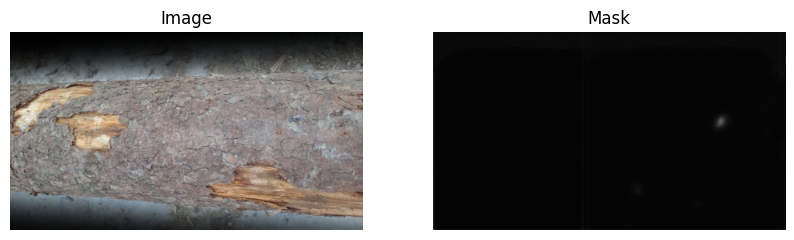

0.9680817 0.008634674


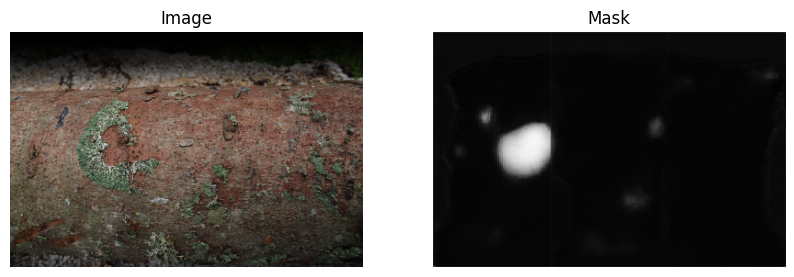

0.2933036 0.013768123


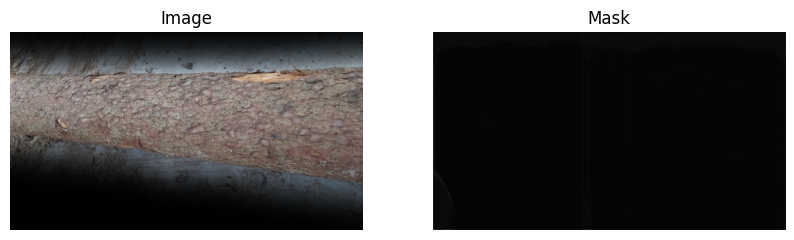

0.99812514 0.011694861


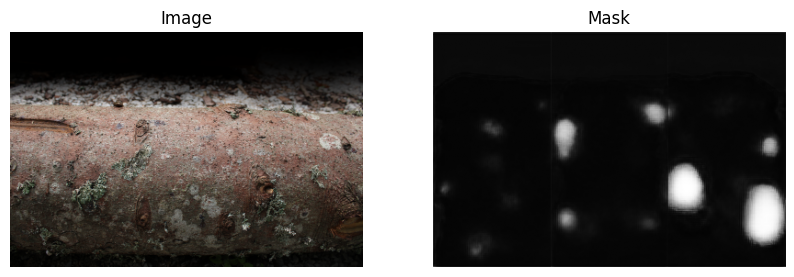

In [ ]:
from mltools.seg.dataset import SegDataset
from mltools import PROCESSED_DIR
from pathlib import Path
from mltools.seg.schema.root import ClassGroupConfig
from mltools.seg.transform import INFERENCE_TRANSFORM
import torch

class_groups = [
    ClassGroupConfig(value=1.0, classes=[1.0]),
    ClassGroupConfig(value=0.6, classes=[0.2, 0.6]),
]
class_groups = None
class_groups = cfg.class_groups

dataset = SegDataset(
    Path(PROCESSED_DIR) / "knots_Min256_vignette",
    cache_amount=0,
    class_groups=class_groups,
)
# load the best model stored in the experiments directory
model_path = Path(
    "../experiments/2026-03-17/23-38-43/checkpoints/best-model-epoch=54-val_dice=0.7028.ckpt"
)
print(f"Loading model from {model_path}")
from mltools.seg.module.seg_module import SegModule

model = SegModule.load_from_checkpoint(model_path, weights_only=False)
model.eval()
for i in range(350, 354):
    image, mask = dataset[i]
    # vignette = apply_vignette(image, (mask * 255).astype(np.uint8), amount=0.8)
    out = INFERENCE_TRANSFORM(image=image)
    inp_image = (
        out["image"].unsqueeze(0).to(next(model.parameters()).device)
    )  # Add batch dimension
    # resize to 256x256
    output = (
        model(inp_image).squeeze(0).detach().cpu().numpy().transpose(1, 2, 0)
    )  # Get the probability of the positive class
    print(output.max(), output.min())
    # image = (image * (output>0.3)).astype(np.uint8)
    show_case(image, output)

In [96]:
from mltools.seg.schema import AugmentationConfig
from mltools.seg.transform.transforms import get_train_transform


def apply_augmentation(image, mask, config: AugmentationConfig):
    transform = get_train_transform(config)
    out = transform(image=image, mask=mask)
    return out["image"], out["mask"]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.01058951..1.0568393].


[0. 1.]
[0. 1.]


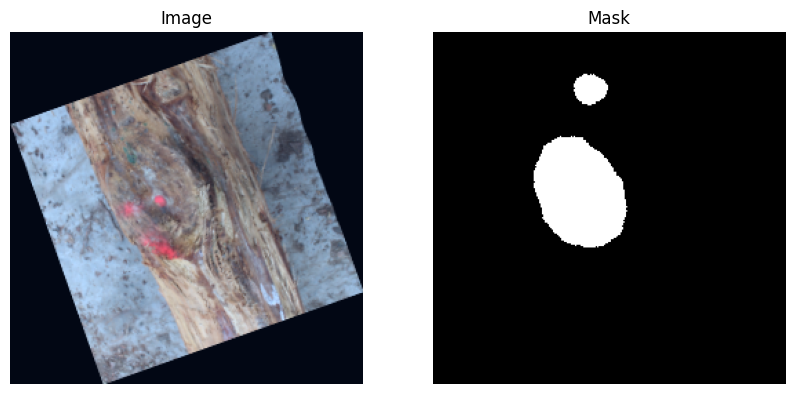

In [97]:
import numpy as np

image, mask = dataset[341]
print(np.unique(mask))
out_image, out_mask = apply_augmentation(image, mask, cfg.augmentation)
out_image = np.transpose(out_image, (1, 2, 0))  # CHW to HWC
out_mask = np.transpose(out_mask, (1, 2, 0))  # CHW to HWC
print(np.unique(out_mask))
# unnormalize imagenet image for visualization
out_image = (out_image * 0.224) + 0.485
show_case(out_image, out_mask)

In [102]:
np.unique(out_mask)

array([0., 1.], dtype=float32)

(256, 256, 1)


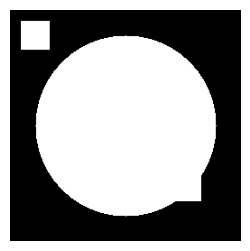

In [2]:
import cv2
from matplotlib import pyplot as plt
import numpy as np

image = np.zeros((256, 256, 1), dtype=np.uint8)
cv2.circle(image, (128, 128), 100, 255, -1)
image[12:44, 12:44] = 255
image[112:212, 112:212] = 255
print(image.shape)
plt.figure(figsize=(3, 3))
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

255.0 1.0


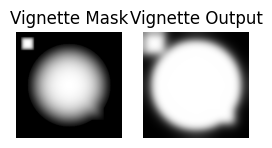

In [ ]:
from mltools.seg.transform.transforms import (
    MaskVignetteTransform,
    ImageMaskTransform,
    get_vignette,
)

vignette_transform = MaskVignetteTransform(steepness=5, midpoint=0.1)
vignette_transform_out = ImageMaskTransform(steepness=10, midpoint=0.1, channel_index=0)
res = vignette_transform(image=image, mask=image)
res_out = vignette_transform_out(
    image=np.ones(shape=(image.shape[0], image.shape[1], 3)), mask=image
)
vignette_mask = res["mask"]
print(np.max(vignette_mask), np.max(res_out["image"]))
# vignette_mask = get_vignette(image, amount=0.02, invert=True)
plt.figure(figsize=(3, 3))
plt.subplot(1, 2, 1)
plt.title("Vignette Mask")
# plt.imshow(np.concatenate([vignette_mask, image, np.ones_like(image)], axis=-1), vmin=0, vmax=1)
plt.imshow(vignette_mask[..., 0], cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.subplot(1, 2, 2)
plt.title("Vignette Output")
plt.imshow(res_out["image"], cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.show()

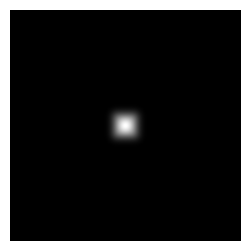

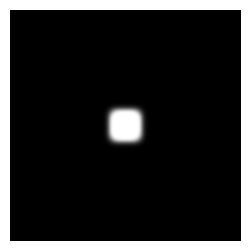

flat_labels shape: (1024,)
labels_indices shape: (256, 256)


IndexError: index 1024 is out of bounds for axis 0 with size 1024

In [ ]:
from scipy.stats import norm

labels = image.astype(np.float32)
mask = (labels > 0).astype(np.uint8) * 255
amount = 0.01

# mask should be uint8 (0 and 255)
dist, labels_indices = cv2.distanceTransformWithLabels(
    mask, cv2.DIST_L2, 5, labelType=cv2.DIST_LABEL_PIXEL
)
# return labels_indices, dist

# The kernel size should be proportional to image resolution
res = min(labels.shape[0:2])
blur_size = int(res * 0.1) | 1  # Must be odd
vignette_map = cv2.GaussianBlur(dist, (blur_size, blur_size), 0)
plt.figure(figsize=(3, 3))
plt.imshow(vignette_map, cmap="gray", vmin=0, vmax=vignette_map.max())
plt.axis("off")
plt.show()

# apply bell curve for falloff control
scale = res * 0.5
vignette_map = norm.cdf(vignette_map, loc=0, scale=(scale * amount))
# vignette_map = 1 - vignette_map
cv2.normalize(vignette_map, vignette_map, 0, 1.0, cv2.NORM_MINMAX)
plt.figure(figsize=(3, 3))
plt.imshow(vignette_map, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.show()

# use labels_indices to index labels
vignette_map = vignette_map[:, :, np.newaxis]
flat_labels = labels[labels > 0].flatten()
# add dim to the end
print("flat_labels shape:", flat_labels.shape)
print("labels_indices shape:", labels_indices.shape)
labels_map = flat_labels[labels_indices - 1][..., np.newaxis]
print("vignette_map shape:", vignette_map.shape)
vignette_map = vignette_map * labels_map
vignette_map = vignette_map.astype(np.float32)
plt.figure(figsize=(3, 3))
plt.imshow(vignette_map.squeeze(), cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.show()